In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [32]:
df = pd.read_csv("hotel_bookings.csv")

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


In [33]:
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris dan kolom: (119390, 32)
Jumlah baris: 119390
Jumlah kolom: 32


In [34]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [36]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [37]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Jumlah Missing Value": missing,
    "Persentase (%)": (missing / len(df) * 100).round(2)
})

missing_df = missing_df[missing_df["Jumlah Missing Value"] > 0]
missing_df.sort_values(
    by="Jumlah Missing Value",
    ascending=False
)

,Jumlah Missing Value,Persentase (%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [38]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 31994


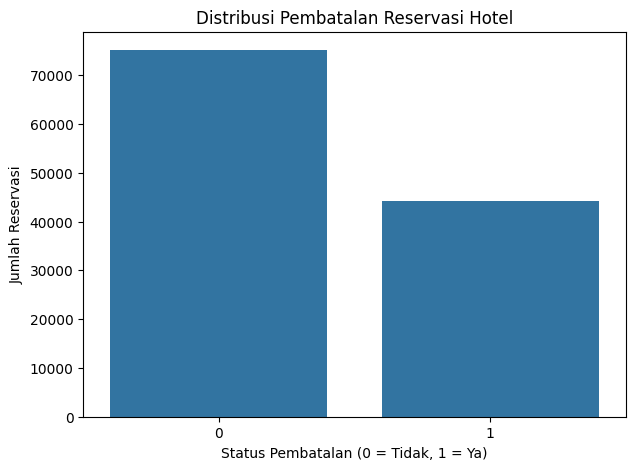

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


In [39]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="is_canceled")

plt.title("Distribusi Pembatalan Reservasi Hotel")
plt.xlabel("Status Pembatalan (0 = Tidak, 1 = Ya)")
plt.ylabel("Jumlah Reservasi")
plt.show()

print(df["is_canceled"].value_counts())
print(df["is_canceled"].value_counts(normalize=True) * 100)

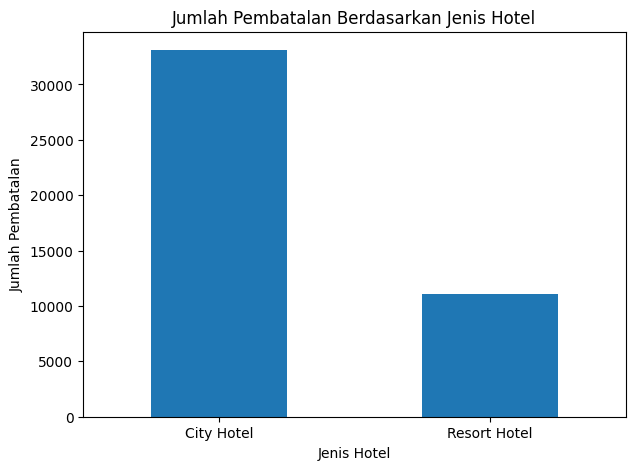

In [40]:
hotel_cancel = df.groupby("hotel")["is_canceled"].sum()

hotel_cancel.plot(kind="bar", figsize=(7, 5))

plt.title("Jumlah Pembatalan Berdasarkan Jenis Hotel")
plt.xlabel("Jenis Hotel")
plt.ylabel("Jumlah Pembatalan")
plt.xticks(rotation=0)
plt.show()

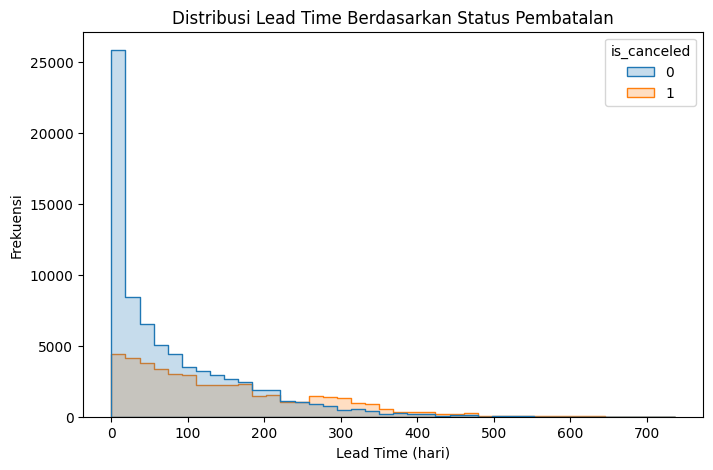

In [41]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="lead_time", hue="is_canceled",
             bins=40, element="step")

plt.title("Distribusi Lead Time Berdasarkan Status Pembatalan")
plt.xlabel("Lead Time (hari)")
plt.ylabel("Frekuensi")
plt.show()

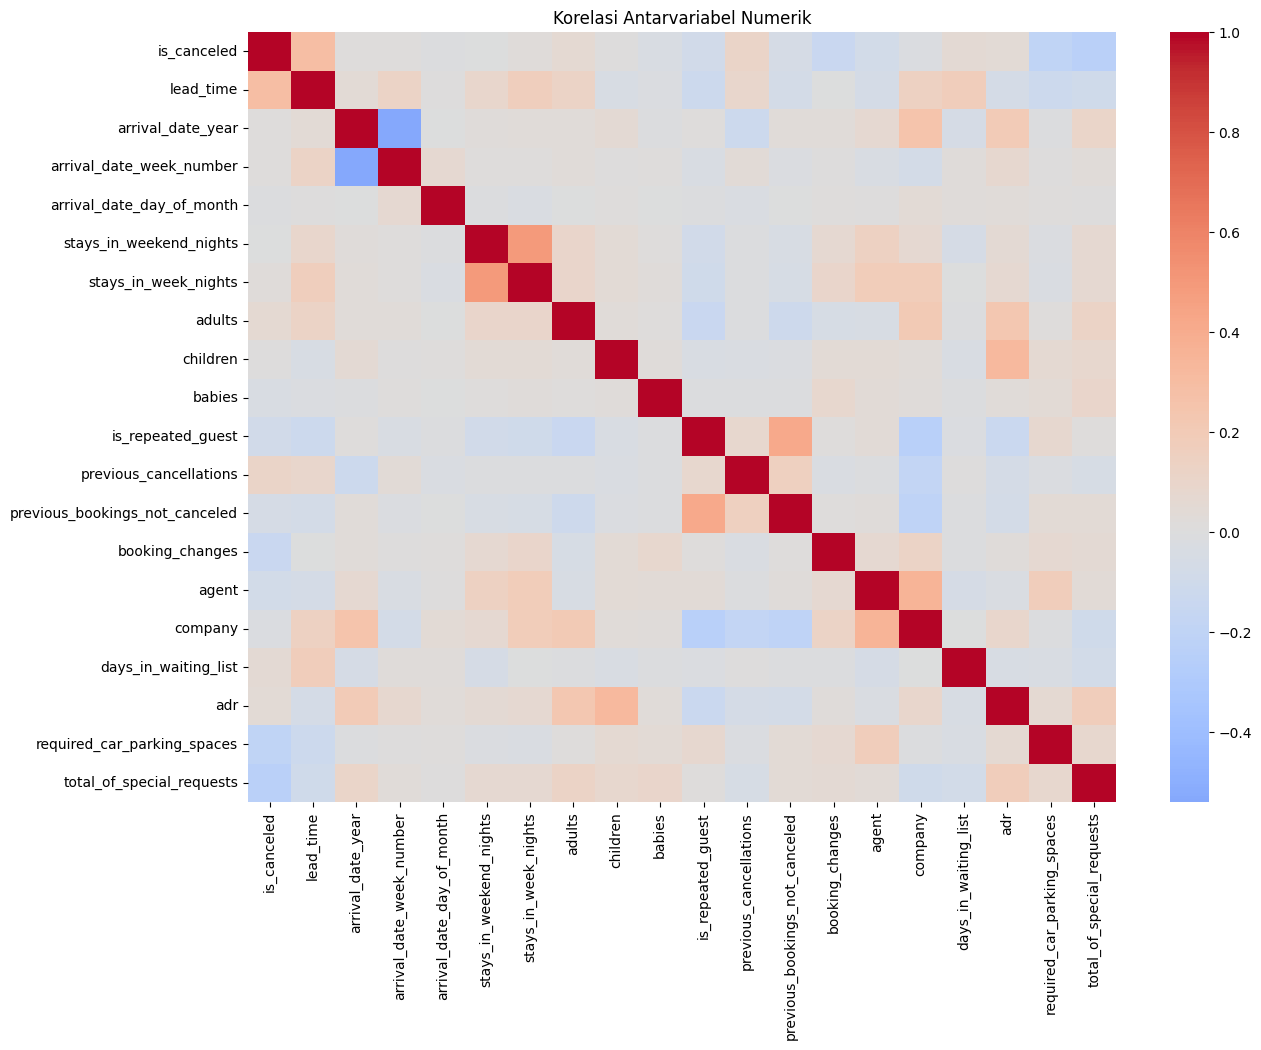

In [42]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Korelasi Antarvariabel Numerik")
plt.show()

In [43]:
# Salinan dataset untuk preprocessing
data = df.copy()

# Menghapus data duplikat
data = data.drop_duplicates()

# Menghapus kolom yang berpotensi menyebabkan target leakage
data = data.drop(
    columns=["reservation_status", "reservation_status_date"],
    errors="ignore"
)

# Menghapus company karena memiliki banyak missing value
data = data.drop(columns=["company"], errors="ignore")

# Menentukan target
y = data["is_canceled"]

# Menentukan fitur
X = data.drop(columns=["is_canceled"])

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Jumlah fitur: 28
Jumlah target: 87396


In [44]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Fitur numerik:", len(numeric_features))
print("Fitur kategorikal:", len(categorical_features))

Fitur numerik: 18
Fitur kategorikal: 10


In [45]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (69916, 28)
Data uji: (17480, 28)


In [47]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        class_weight="balanced"
    ))
])

In [48]:
print("Proses training dimulai...")

model.fit(X_train, y_train)

print("Training selesai.")

Proses training dimulai...
Training selesai.


In [49]:
y_pred = model.predict(X_test)

print("Prediksi selesai.")
print("Lima hasil prediksi:", y_pred[:5])
print("Lima nilai aktual:", y_test.iloc[:5].values)

Prediksi selesai.
Lima hasil prediksi: [0 1 1 1 0]
Lima nilai aktual: [0 0 0 1 1]


In [50]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.7397
Precision : 0.5152
Recall    : 0.8978
F1-Score  : 0.6547


In [51]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Tidak Dibatalkan", "Dibatalkan"],
    zero_division=0
))

                  precision    recall  f1-score   support

Tidak Dibatalkan       0.95      0.68      0.79     12675
      Dibatalkan       0.52      0.90      0.65      4805

        accuracy                           0.74     17480
       macro avg       0.73      0.79      0.72     17480
    weighted avg       0.83      0.74      0.75     17480



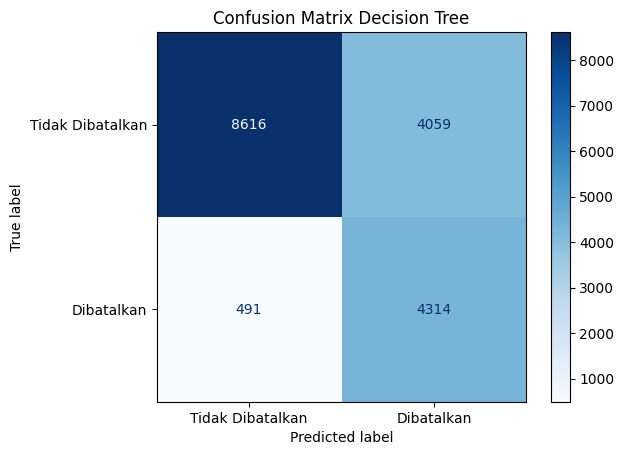

In [52]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Tidak Dibatalkan", "Dibatalkan"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix Decision Tree")
plt.show()

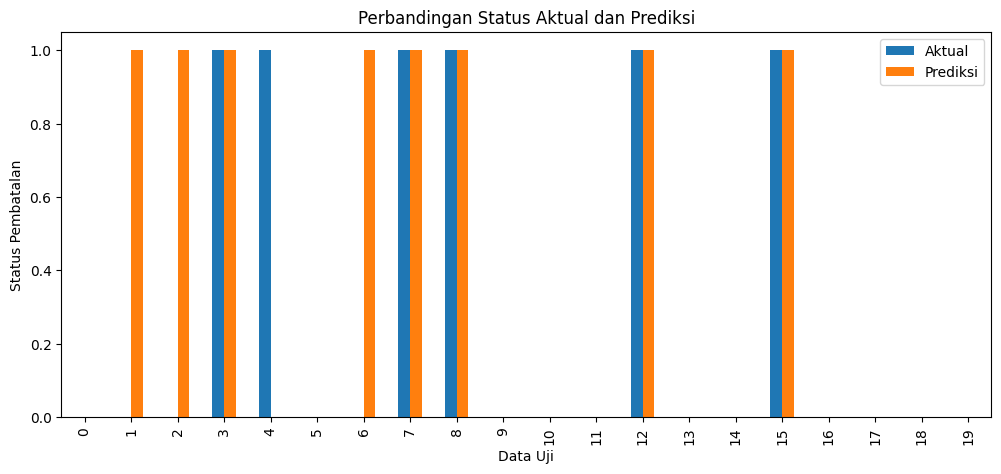

In [53]:
comparison = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred
})

comparison.head(20).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Perbandingan Status Aktual dan Prediksi")
plt.xlabel("Data Uji")
plt.ylabel("Status Pembatalan")
plt.legend(["Aktual", "Prediksi"])
plt.show()

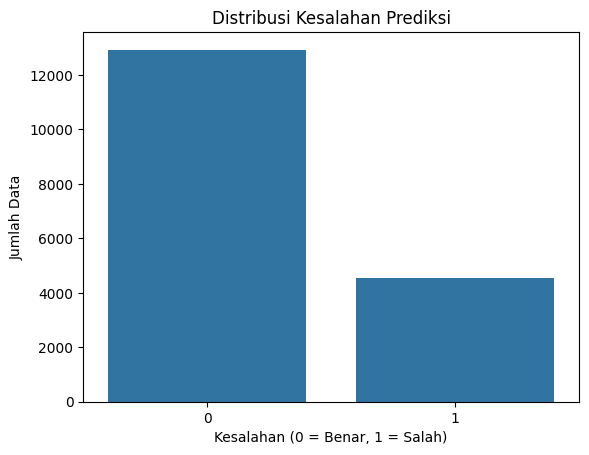

Jumlah prediksi benar: 12930
Jumlah prediksi salah: 4550


In [54]:
error = (y_test.values != y_pred).astype(int)

sns.countplot(x=error)

plt.title("Distribusi Kesalahan Prediksi")
plt.xlabel("Kesalahan (0 = Benar, 1 = Salah)")
plt.ylabel("Jumlah Data")
plt.show()

print("Jumlah prediksi benar:", (error == 0).sum())
print("Jumlah prediksi salah:", (error == 1).sum())

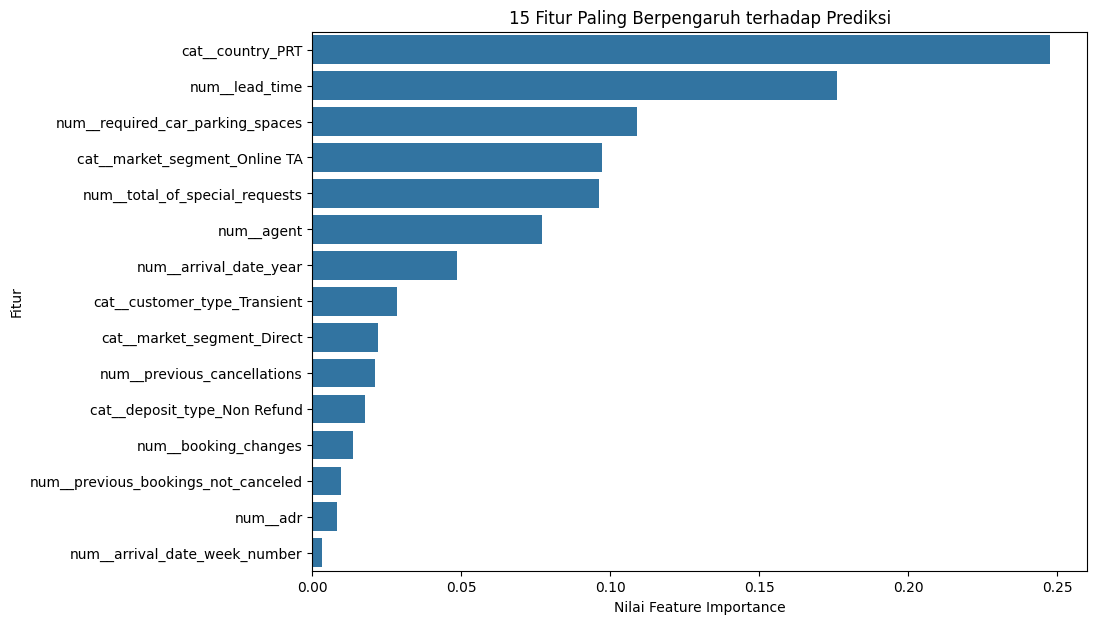

,Fitur,Importance
167,cat__country_PRT,0.247704
0,num__lead_time,0.176109
16,num__required_car_parking_spaces,0.109016
213,cat__market_segment_Online TA,0.097080
17,num__total_of_special_requests,0.096317
13,num__agent,0.076941
1,num__arrival_date_year,0.048422
246,cat__customer_type_Transient,0.028506
210,cat__market_segment_Direct,0.022112
10,num__previous_cancellations,0.020856


In [55]:
# Mengambil nama fitur setelah preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Mengambil nilai feature importance
importance = model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)

# Menampilkan 15 fitur terpenting
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Fitur"
)

plt.title("15 Fitur Paling Berpengaruh terhadap Prediksi")
plt.xlabel("Nilai Feature Importance")
plt.ylabel("Fitur")
plt.show()

display(top_features)

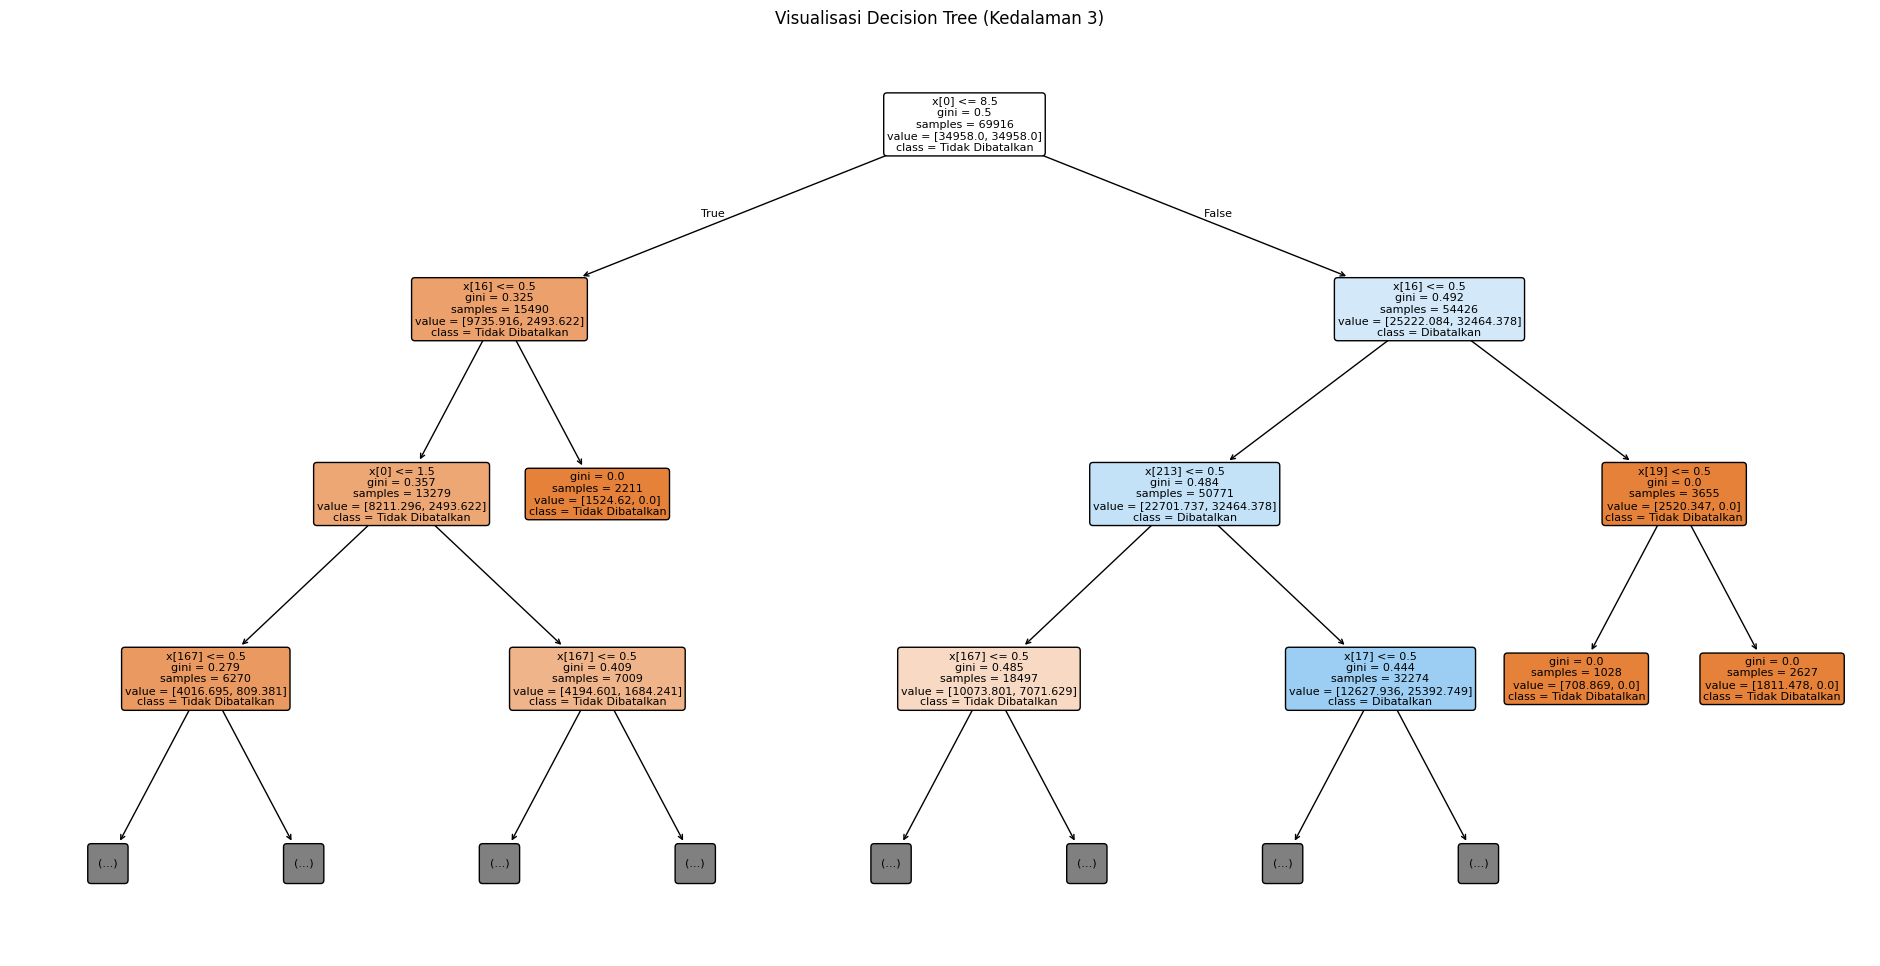

In [56]:
plt.figure(figsize=(24, 12))

plot_tree(
    model.named_steps["classifier"],
    max_depth=3,
    filled=True,
    rounded=True,
    class_names=["Tidak Dibatalkan", "Dibatalkan"],
    fontsize=8
)

plt.title("Visualisasi Decision Tree (Kedalaman 3)")
plt.show()

In [57]:

import joblib
import os

# Membuat folder untuk menyimpan model
os.makedirs("deployment", exist_ok=True)

# Menyimpan model Decision Tree beserta preprocessing
joblib.dump(model, "deployment/decision_tree_hotel.pkl")

print("Model berhasil disimpan!")


Model berhasil disimpan!


In [58]:

import joblib
import pandas as pd

# Memuat model yang telah disimpan
model_deploy = joblib.load(
    "deployment/decision_tree_hotel.pkl"
)

# Mengambil satu data reservasi untuk pengujian
data_reservasi = X_test.iloc[[0]]

# Melakukan prediksi
hasil_prediksi = model_deploy.predict(data_reservasi)[0]

# Mengubah hasil prediksi menjadi keterangan
status = (
    "Dibatalkan"
    if hasil_prediksi == 1
    else "Tidak Dibatalkan"
)

print("Hasil Prediksi Reservasi Hotel")
print("Status:", status)

# Menampilkan probabilitas prediksi jika tersedia
if hasattr(model_deploy, "predict_proba"):
    probabilitas = model_deploy.predict_proba(
        data_reservasi
    )[0]

    print(
        f"Probabilitas tidak dibatalkan: {probabilitas[0]:.2%}"
    )
    print(
        f"Probabilitas dibatalkan: {probabilitas[1]:.2%}"
    )


Hasil Prediksi Reservasi Hotel
Status: Tidak Dibatalkan
Probabilitas tidak dibatalkan: 87.69%
Probabilitas dibatalkan: 12.31%
